## importing libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from pathlib import Path
print("libraries imported successfully ")



libraries imported successfully 


## loading data and setting up file paths

In [4]:
file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# locate dataset 
possible_paths = [
    Path("data/raw") / file_name,
    Path("../data/raw") / file_name
]

file_path=next(
(path for path in possible_paths if path.exists()), None
)

#  checking whether the dataset exists 
if file_path is None:
    raise FileNotFoundError(f"{file_name} not found!!")

# load dataset 
df= pd.read_csv(file_path)

print("data_set loaded succesfully")


data_set loaded succesfully


## exploring data 

In [ ]:
df.head()


In [7]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [10]:
#  dimensions of dataset 
print("Dataset shape: ", df.shape)
print("Total rows: ", df.shape[0])
print("Total cols: ", df.shape[1])


Dataset shape:  (7043, 21)
Total rows:  7043
Total cols:  21


In [15]:
#  col names and datatypes 
df.info()
print("data types of columns: \n", df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [16]:
# understanding numerical cols
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [17]:
# inspecting categorical cols 
df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## initial data quauality checks 

In [19]:
# checking missing values 
missing_vals=df.isnull().sum()
print("Missing values in each cols:\n", missing_vals)

# cols with missing vals 
print("Cols with missing vals: \n", missing_vals[missing_vals>0])


Missing values in each cols:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Cols with missing vals: 
 Series([], dtype: int64)


In [21]:
# checking for duplicates 
print("Total duplicated rows :", df.duplicated())


Total duplicated rows : 0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool


In [26]:
# check unique customers 
print("Unique customers:", df["customerID"].unique())
print("Total unique customers:", df["customerID"].nunique())

Unique customers: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Total unique customers: 7043


In [27]:
# check balnk values in total charges:
blank_total_charges=(
    df["TotalCharges"].astype(str).str.strip().eq("").sum()

)
print("Blank Total charges: ", blank_total_charges)

Blank Total charges:  11


In [34]:
#  churn : 

print("total unique churn counts: ", df["Churn"].nunique())
print("churn values:", df["Churn"].unique())
print("value count of churn:\n", df["Churn"].value_counts())

# churn percentage
churn_perc=df["Churn"].value_counts(normalize=True)*100
print("Churn Percentage:\n", churn_perc)


total unique churn counts:  2
churn values: ['No' 'Yes']
value count of churn:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn Percentage:
 Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


## simple visualization: 

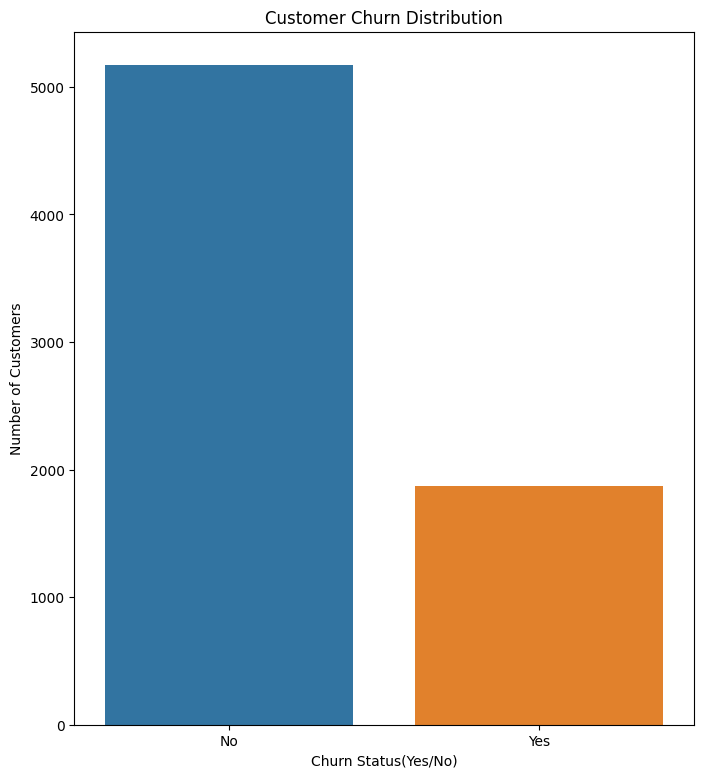

In [42]:
plt.figure(figsize=(8,9))
sns.countplot(
    data=df,
    x="Churn" # column to plot
   
    
)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status(Yes/No)")
plt.ylabel("Number of Customers")

plt.show()

## Initial dataset summary: 


In [49]:
dataset_summary={
    "Total rows ": df.shape[0],
    "Total columns ": df.shape[1],
    "Duplicate Rows": df.duplicated().sum(),
    "Unique Customers": df["customerID"].nunique(),
    "Missing values": df.isnull().sum().sum(),
    "Blank TotalCharges" : blank_total_charges,
    "Churn Percentage(Yes)": churn_perc["Yes"]
    # "Churn Percentage": churn_perc["No"]
}

summary_df=pd.DataFrame(
    dataset_summary.items(),
    columns=["Metrics", "Value"]
    )

summary_df

,Metrics,Value
0,Total rows,7043.000000
1,Total columns,21.000000
2,Duplicate Rows,0.000000
3,Unique Customers,7043.000000
4,Missing values,0.000000
5,Blank TotalCharges,11.000000
6,Churn Percentage(Yes),26.536987
